# Embedding Model Selection

This notebook justifies the selection of **E5-large** with a **weighted definition + 5 examples** strategy as the optimal configuration for Word Sense Disambiguation.

## Experiment Setup

**Task:** Predict the correct GermaNet sense for German words in context using cosine similarity between context and sense embeddings.

**Evaluation:** 93 manually annotated test instances across 10 polysemous German words.

**Models Tested:** 5 multilingual sentence transformers  
**Text Variants Tested:** 9 different sense representation strategies


In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, HTML, Markdown

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

def styled_df(df, highlight_first=False, caption=None):
    """Apply consistent styling to dataframes."""
    styler = df.style.format(precision=3).set_properties(**{
        'text-align': 'center',
        'font-size': '11pt',
    }).set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#f0f0f0'), ('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('padding', '8px')]},
    ])
    if highlight_first and len(df) > 0:
        styler = styler.apply(lambda x: ['background-color: #d4edda' if i == 0 else '' for i in range(len(x))], axis=0)
    if caption:
        styler = styler.set_caption(caption)
    return styler

## 1. Load Results

In [122]:
# Load results
results_path = Path('../data/evaluation/quick_eval/embedding_comparison.csv')
df = pd.read_csv(results_path)

# Create readable names
model_name_map = {
    # Multilingual models
    'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2': 'MiniLM-L12',
    'sentence-transformers/distiluse-base-multilingual-cased-v2': 'distilUSE',
    'sentence-transformers/paraphrase-multilingual-mpnet-base-v2': 'mpnet-base',
    'sentence-transformers/LaBSE': 'LaBSE',
    'intfloat/multilingual-e5-base': 'E5-base',
    'intfloat/multilingual-e5-large': 'E5-large',
    'BAAI/bge-m3': 'BGE-M3',
}

variant_name_map = {
    # Newer naming
    'baseline': 'Baseline',
    'llm_definition': 'Definition',
    'llm_example_0': 'Example (1)',
    'llm_example_1': 'Example (2)',
    'llm_example_2': 'Example (3)',
    'llm_example_3': 'Example (4)',
    'llm_example_4': 'Example (5)',
    '__weighted_def_plus_examples': 'Weighted Def + 5Ex',
}

df['model'] = df['model_name'].map(model_name_map).fillna(df['model_name'])
df['variant'] = df['text_variant'].map(variant_name_map).fillna(df['text_variant'])

# Sort by accuracy
df = df.sort_values('accuracy', ascending=False)

## 2. Full Results Ranking

All 45 configurations ranked by accuracy:


In [123]:
# Display all results with styling
results_display = df[['model', 'variant', 'accuracy', 'top3', 'mrr']].copy()
results_display.insert(0, 'Rank', range(1, len(results_display) + 1))
results_display.columns = ['Rank', 'Model', 'Variant', 'Accuracy', 'Top-3', 'MRR']

# Style the dataframe
styled = results_display.style.format({
    'Accuracy': '{:.1%}',
    'Top-3': '{:.1%}',
    'MRR': '{:.3f}'
}).background_gradient(
    subset=['Accuracy'], cmap='RdYlGn', vmin=0.2, vmax=0.6
).set_properties(**{
    'text-align': 'center',
    'font-size': '10pt',
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), 
                                  ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
    {'selector': 'td', 'props': [('padding', '8px')]},
    {'selector': 'tr:first-child', 'props': [('background-color', '#d4edda !important')]},
]).set_caption("🏆 All Configurations Ranked by Accuracy")

display(styled)

,Rank,Model,Variant,Accuracy,Top-3,MRR
31,1,E5-large,Weighted Def + 5Ex,54.8%,96.8%,0.725
39,2,BGE-M3,Weighted Def + 5Ex,51.6%,96.8%,0.717
7,3,mpnet-base,Weighted Def + 5Ex,47.3%,89.2%,0.677
30,4,E5-large,Example (5),47.3%,90.3%,0.679
6,5,mpnet-base,Example (5),46.2%,89.2%,0.682
23,6,E5-base,Weighted Def + 5Ex,46.2%,93.5%,0.676
29,7,E5-large,Example (4),46.2%,79.6%,0.641
15,8,LaBSE,Weighted Def + 5Ex,46.2%,92.5%,0.680
38,9,BGE-M3,Example (5),45.2%,94.6%,0.673
2,10,mpnet-base,Example (1),45.2%,86.0%,0.662


## 3. Best: E5-large + Weighted Def + 5Ex

**Accuracy: 54.8%** — The highest among all 45 configurations.


In [124]:
# Get best configuration
winner = df.iloc[0]

display(HTML(f"""
<div style="background: linear-gradient(135deg, #11998e 0%, #38ef7d 100%); padding: 25px; border-radius: 12px; color: white; margin: 10px 0;">
    <h2 style="margin: 0 0 5px 0;">🥇 Selected Configuration</h2>
    <p style="margin: 0 0 20px 0; opacity: 0.9; font-size: 14px;">Highest accuracy among all {len(df)} tested configurations</p>
    
    <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 20px;">
        <div style="background: rgba(255,255,255,0.15); padding: 20px; border-radius: 10px;">
            <h4 style="margin: 0 0 15px 0; border-bottom: 1px solid rgba(255,255,255,0.3); padding-bottom: 10px;">Configuration</h4>
            <div style="margin-bottom: 10px;">
                <span style="opacity: 0.8;">Model:</span><br>
                <span style="font-size: 18px; font-weight: bold;">{winner['model']}</span>
            </div>
            <div>
                <span style="opacity: 0.8;">Text Variant:</span><br>
                <span style="font-size: 18px; font-weight: bold;">{winner['variant']}</span>
            </div>
        </div>
        
        <div style="background: rgba(255,255,255,0.15); padding: 20px; border-radius: 10px;">
            <h4 style="margin: 0 0 15px 0; border-bottom: 1px solid rgba(255,255,255,0.3); padding-bottom: 10px;">Performance Metrics</h4>
            <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px;">
                <div>
                    <span style="opacity: 0.8; font-size: 12px;">Accuracy</span>
                    <div style="font-size: 24px; font-weight: bold;">{winner['accuracy']:.1%}</div>
                </div>
                <div>
                    <span style="opacity: 0.8; font-size: 12px;">Top-3</span>
                    <div style="font-size: 24px; font-weight: bold;">{winner['top3']:.1%}</div>
                </div>
                <div>
                    <span style="opacity: 0.8; font-size: 12px;">Top-5</span>
                    <div style="font-size: 24px; font-weight: bold;">{winner['top5']:.1%}</div>
                </div>
                <div>
                    <span style="opacity: 0.8; font-size: 12px;">MRR</span>
                    <div style="font-size: 24px; font-weight: bold;">{winner['mrr']:.3f}</div>
                </div>
            </div>
        </div>
    </div>
</div>
"""))

## 4. Comparison to Alternatives

How much better is E5-large + Weighted Def + 5Ex compared to other reasonable choices?


In [125]:
# Top 10 comparison with styled table
top10 = df.head(10).copy()
top10['Rank'] = range(1, len(top10) + 1)
top10['Gap'] = top10['accuracy'] - winner['accuracy']

comparison = top10[['Rank', 'model', 'variant', 'accuracy', 'Gap']].copy()
comparison.columns = ['Rank', 'Model', 'Variant', 'Accuracy', 'Gap to #1']

styled = comparison.style.format({
    'Accuracy': '{:.1%}',
    'Gap to #1': '{:+.1%}'
}).background_gradient(
    subset=['Accuracy'], cmap='RdYlGn', vmin=0.3, vmax=0.6
).applymap(
    lambda x: 'color: #28a745; font-weight: bold' if x == 0 else 'color: #dc3545',
    subset=['Gap to #1']
).set_properties(**{
    'text-align': 'center',
    'font-size': '11pt',
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), 
                                  ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
    {'selector': 'td', 'props': [('padding', '8px')]},
]).set_caption("🔝 Top 10 Configurations")

display(styled)

/var/folders/m4/prj94mxs4pn6lk9nc4z7vrc80000gn/T/ipykernel_52043/227137367.py:14: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  ).applymap(


,Rank,Model,Variant,Accuracy,Gap to #1
31,1,E5-large,Weighted Def + 5Ex,54.8%,+0.0%
39,2,BGE-M3,Weighted Def + 5Ex,51.6%,-3.2%
7,3,mpnet-base,Weighted Def + 5Ex,47.3%,-7.5%
30,4,E5-large,Example (5),47.3%,-7.5%
6,5,mpnet-base,Example (5),46.2%,-8.6%
23,6,E5-base,Weighted Def + 5Ex,46.2%,-8.6%
29,7,E5-large,Example (4),46.2%,-8.6%
15,8,LaBSE,Weighted Def + 5Ex,46.2%,-8.6%
38,9,BGE-M3,Example (5),45.2%,-9.7%
2,10,mpnet-base,Example (1),45.2%,-9.7%



### Highlight key comparisons

In [126]:
# Build comparison cards
html_parts = []

# #1 vs #2 comparison
if len(df) > 1:
    second_best = df.iloc[1]
    gap = winner['accuracy'] - second_best['accuracy']
    rel_gap = (gap / second_best['accuracy']) * 100 if second_best['accuracy'] > 0 else 0
    
    html_parts.append(f"""
    <div style="background: #fff; border: 2px solid #e0e0e0; border-radius: 10px; padding: 20px; margin-bottom: 15px;">
        <h4 style="margin: 0 0 15px 0; color: #2c3e50;">🥇 vs 🥈 Runner-up</h4>
        <div style="display: grid; grid-template-columns: 1fr auto 1fr; gap: 15px; align-items: center;">
            <div style="background: #d4edda; padding: 15px; border-radius: 8px; text-align: center;">
                <div style="font-size: 12px; color: #666;">#{1}</div>
                <div style="font-weight: bold; color: #155724;">{winner['model']}</div>
                <div style="font-size: 11px; color: #666;">{winner['variant']}</div>
                <div style="font-size: 24px; font-weight: bold; color: #28a745;">{winner['accuracy']:.1%}</div>
            </div>
            <div style="text-align: center;">
                <div style="font-size: 24px;">→</div>
                <div style="background: #28a745; color: white; padding: 5px 12px; border-radius: 15px; font-weight: bold;">
                    +{gap:.1%}
                </div>
                <div style="font-size: 11px; color: #666; margin-top: 5px;">({rel_gap:.1f}% relative)</div>
            </div>
            <div style="background: #f8f9fa; padding: 15px; border-radius: 8px; text-align: center;">
                <div style="font-size: 12px; color: #666;">#{2}</div>
                <div style="font-weight: bold; color: #495057;">{second_best['model']}</div>
                <div style="font-size: 11px; color: #666;">{second_best['variant']}</div>
                <div style="font-size: 24px; font-weight: bold; color: #6c757d;">{second_best['accuracy']:.1%}</div>
            </div>
        </div>
    </div>
    """)

# vs Baseline comparison
baseline_configs = df[df['text_variant'] == 'baseline']
if len(baseline_configs) > 0:
    best_baseline = baseline_configs.iloc[0]
    gap = winner['accuracy'] - best_baseline['accuracy']
    rel_gap = (gap / best_baseline['accuracy']) * 100 if best_baseline['accuracy'] > 0 else 0
    
    html_parts.append(f"""
    <div style="background: #fff; border: 2px solid #e0e0e0; border-radius: 10px; padding: 20px;">
        <h4 style="margin: 0 0 15px 0; color: #2c3e50;">🥇 vs 📊 Best Baseline</h4>
        <div style="display: grid; grid-template-columns: 1fr auto 1fr; gap: 15px; align-items: center;">
            <div style="background: #d4edda; padding: 15px; border-radius: 8px; text-align: center;">
                <div style="font-size: 12px; color: #666;">Selected</div>
                <div style="font-weight: bold; color: #155724;">{winner['model']}</div>
                <div style="font-size: 11px; color: #666;">{winner['variant']}</div>
                <div style="font-size: 24px; font-weight: bold; color: #28a745;">{winner['accuracy']:.1%}</div>
            </div>
            <div style="text-align: center;">
                <div style="font-size: 24px;">→</div>
                <div style="background: #28a745; color: white; padding: 5px 12px; border-radius: 15px; font-weight: bold;">
                    +{gap:.1%}
                </div>
                <div style="font-size: 11px; color: #666; margin-top: 5px;">({rel_gap:.1f}% relative)</div>
            </div>
            <div style="background: #fff3cd; padding: 15px; border-radius: 8px; text-align: center;">
                <div style="font-size: 12px; color: #666;">Baseline</div>
                <div style="font-weight: bold; color: #856404;">{best_baseline['model']}</div>
                <div style="font-size: 11px; color: #666;">{best_baseline['variant']}</div>
                <div style="font-size: 24px; font-weight: bold; color: #856404;">{best_baseline['accuracy']:.1%}</div>
            </div>
        </div>
    </div>
    """)
else:
    html_parts.append("""
    <div style="background: #fff3cd; border: 1px solid #ffc107; border-radius: 8px; padding: 15px; color: #856404;">
        <strong>Note:</strong> No baseline configuration found in current results.
    </div>
    """)

display(HTML(''.join(html_parts)))

## 5. Visualize Best model vs Alternatives

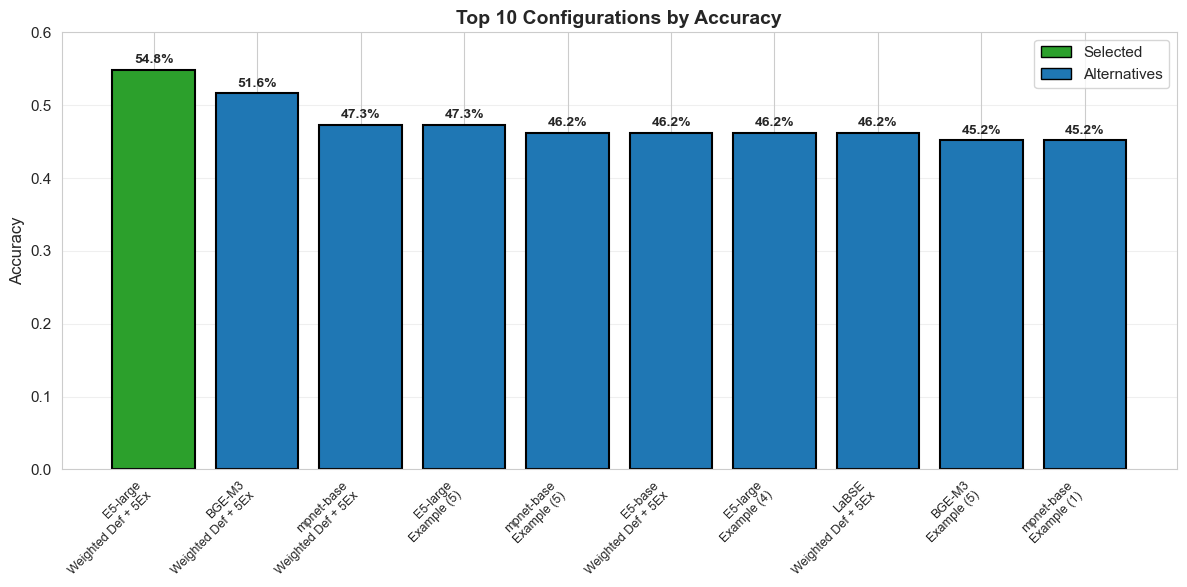

In [127]:
# Bar chart showing top 10
fig, ax = plt.subplots(figsize=(12, 6))

top10_plot = df.head(10).copy()
labels = [f"{row['model']}\n{row['variant']}" for _, row in top10_plot.iterrows()]
colors = ['#2ca02c' if i == 0 else '#1f77b4' for i in range(len(top10_plot))]

bars = ax.bar(range(len(top10_plot)), top10_plot['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

# Annotate bars with accuracy
for i, (bar, acc) in enumerate(zip(bars, top10_plot['accuracy'])):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
            f'{acc:.1%}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
ax.set_xticks(range(len(top10_plot)))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Top 10 Configurations by Accuracy', fontsize=14, fontweight='bold')
ax.set_ylim(0, 0.6)
ax.grid(axis='y', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ca02c', edgecolor='black', label='Selected'),
                   Patch(facecolor='#1f77b4', edgecolor='black', label='Alternatives')]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()


## 6. Heatmap: All Configurations

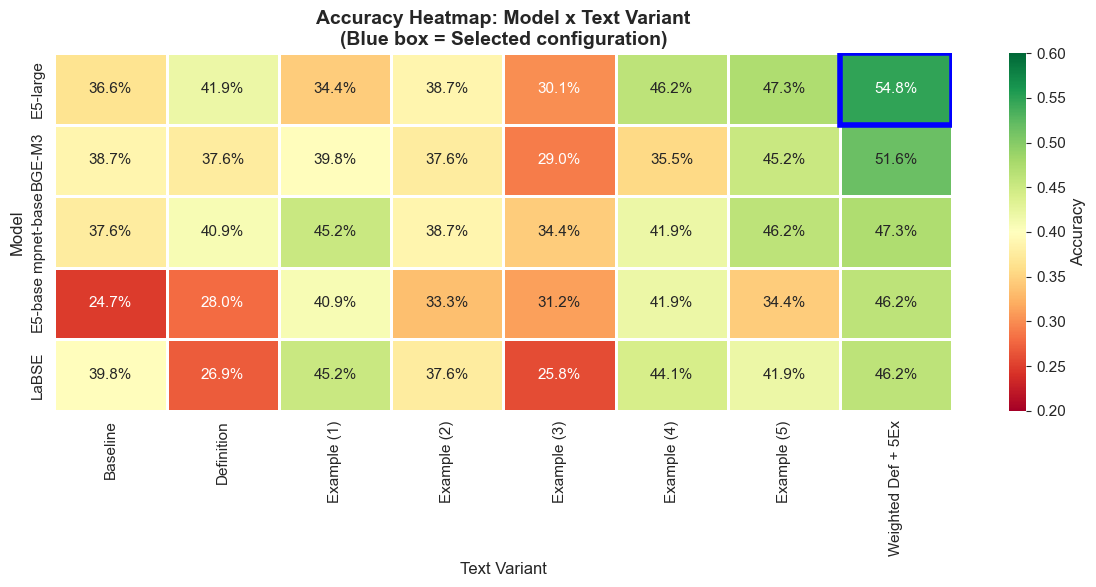

In [128]:
# Restore original order for df
df_sorted = pd.read_csv(results_path)
df_sorted['model'] = df_sorted['model_name'].map(model_name_map).fillna(df_sorted['model_name'])
df_sorted['variant'] = df_sorted['text_variant'].map(variant_name_map).fillna(df_sorted['text_variant'])

if df_sorted.empty:
    print('No results available for heatmap.')
else:
    # Create pivot table
    pivot = df_sorted.pivot(index='model', columns='variant', values='accuracy')
    col_order = [
        'Baseline',
        'Definition',
        'Example (1)',
        'Example (2)',
        'Example (3)',
        'Example (4)',
        'Example (5)',
        'Weighted Def + 5Ex',
    ]
    available_cols = [col for col in col_order if col in pivot.columns]
    if not available_cols:
        print('No variant columns available for heatmap.')
    else:
        pivot = pivot[available_cols]

        # Sort by max accuracy
        pivot['max_acc'] = pivot.max(axis=1)
        pivot = pivot.sort_values('max_acc', ascending=False).drop('max_acc', axis=1)

        # Plot heatmap
        plt.figure(figsize=(12, 6))
        sns.heatmap(pivot, annot=True, fmt='.1%', cmap='RdYlGn',
                    vmin=0.2, vmax=0.6, cbar_kws={'label': 'Accuracy'},
                    linewidths=2, linecolor='white')

        # Highlight winner cell
        winner_variant = variant_name_map.get(winner['text_variant'], winner['text_variant'])
        winner_model = winner['model']
        if winner_model in pivot.index and winner_variant in pivot.columns:
            winner_row = list(pivot.index).index(winner_model)
            winner_col = list(pivot.columns).index(winner_variant)
            plt.gca().add_patch(plt.Rectangle((winner_col, winner_row), 1, 1,
                                               fill=False, edgecolor='blue', lw=4))

        plt.title('Accuracy Heatmap: Model x Text Variant\n(Blue box = Selected configuration)',
                  fontsize=14, fontweight='bold')
        plt.xlabel('Text Variant', fontsize=12)
        plt.ylabel('Model', fontsize=12)
        plt.tight_layout()
        plt.show()

## 7. Why E5-large?

### Model Comparison (with Weighted Def + 5Ex text variant)


,Rank,Model,Accuracy,Top-3,MRR
31,1,E5-large,54.8%,96.8%,0.725
39,2,BGE-M3,51.6%,96.8%,0.717
7,3,mpnet-base,47.3%,89.2%,0.677
15,4,LaBSE,46.2%,92.5%,0.680
23,5,E5-base,46.2%,93.5%,0.676


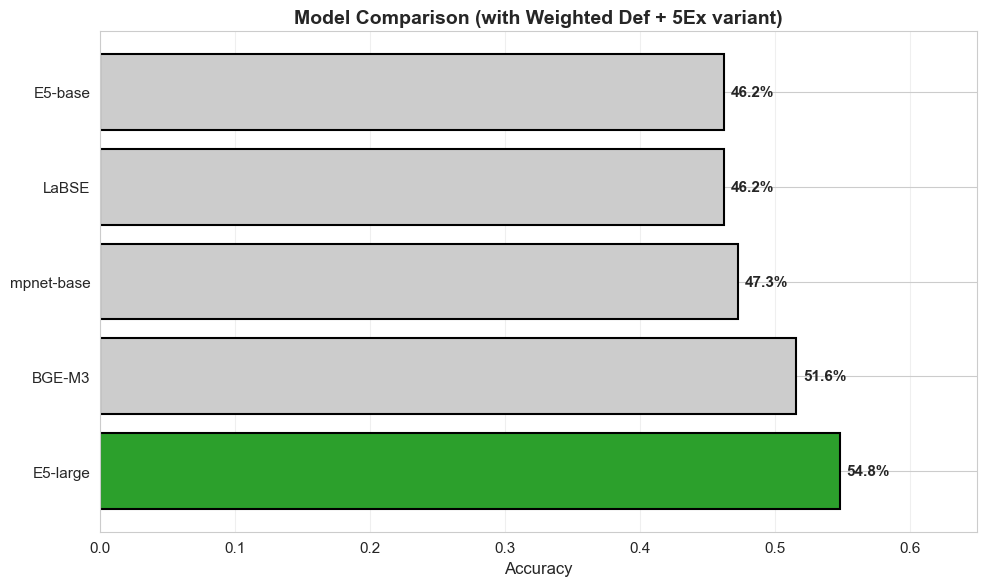

In [129]:
# Filter to selected variant only
selected_variant = variant_name_map.get(winner['text_variant'], winner['text_variant'])
variant_df = df_sorted[df_sorted['variant'] == selected_variant].copy()
variant_df = variant_df.sort_values('accuracy', ascending=False)

# Display styled table
display(HTML(f"<h4>📊 Model Performance with <code>{selected_variant}</code> Text Variant</h4>"))

model_comparison = variant_df[['model', 'accuracy', 'top3', 'mrr']].copy()
model_comparison.insert(0, 'Rank', range(1, len(model_comparison) + 1))
model_comparison.columns = ['Rank', 'Model', 'Accuracy', 'Top-3', 'MRR']

styled = model_comparison.style.format({
    'Accuracy': '{:.1%}',
    'Top-3': '{:.1%}',
    'MRR': '{:.3f}'
}).background_gradient(
    subset=['Accuracy'], cmap='RdYlGn', vmin=0.4, vmax=0.6
).set_properties(**{
    'text-align': 'center',
    'font-size': '11pt',
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), 
                                  ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
    {'selector': 'td', 'props': [('padding', '8px')]},
])

display(styled)

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2ca02c' if m == winner['model'] else '#cccccc' for m in variant_df['model']]
bars = ax.barh(variant_df['model'], variant_df['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

for bar, acc in zip(bars, variant_df['accuracy']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, 
            f'{acc:.1%}', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Accuracy', fontsize=12)
ax.set_title(f'Model Comparison (with {selected_variant} variant)', fontsize=14, fontweight='bold')
ax.set_xlim(0, 0.65)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Justification for E5-large:**
- Highest accuracy among all models when paired with Weighted Def + 5Ex
- E5 models are specifically trained for retrieval/similarity tasks (our use case)
- Larger embedding dimension (1024) captures more semantic nuance


## 8. Why Weighted Def + 5 Examples?

### Text Variant Comparison (with E5-large model)


,Variant,Accuracy,Top-3,MRR
24,Baseline,36.6%,81.7%,0.617
25,Definition,41.9%,86.0%,0.643
26,Example (1),34.4%,81.7%,0.586
27,Example (2),38.7%,84.9%,0.622
28,Example (3),30.1%,86.0%,0.564
29,Example (4),46.2%,79.6%,0.641
30,Example (5),47.3%,90.3%,0.679
31,Weighted Def + 5Ex,54.8%,96.8%,0.725


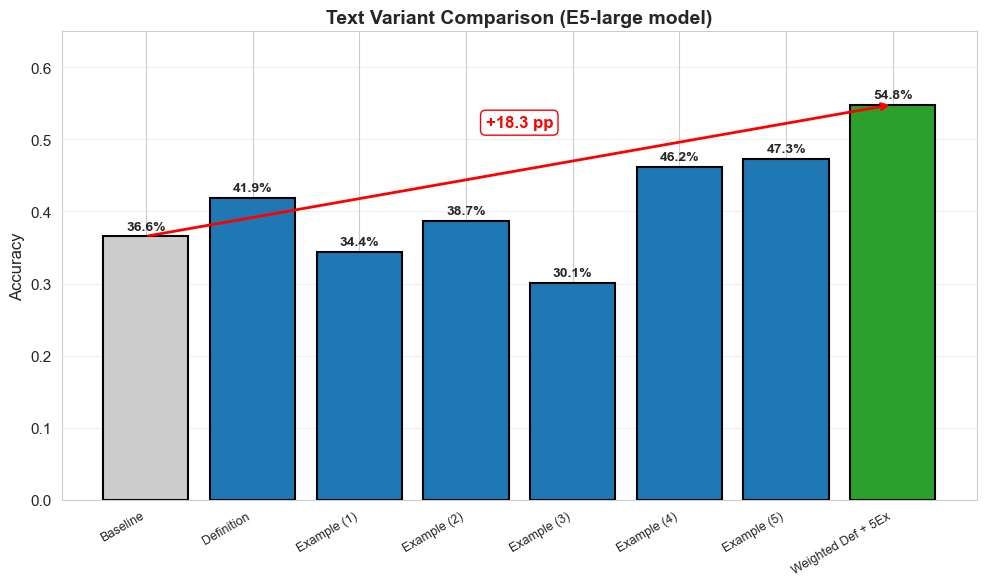

In [130]:
# Filter to E5-large only
e5large_df = df_sorted[df_sorted['model'] == 'E5-large'].copy()
if e5large_df.empty:
    display(HTML('<div style="background: #f8d7da; padding: 15px; border-radius: 8px; color: #721c24;">No E5-large rows found.</div>'))
else:
    # Reorder to show progression
    variant_order = [
        'Baseline', 'Definition', 'Example (1)', 'Example (2)', 'Example (3)',
        'Example (4)', 'Example (5)', 'Weighted Def + 5Ex',
    ]
    available_variants = list(e5large_df['variant'].unique())
    ordered_variants = [v for v in variant_order if v in available_variants]
    ordered_variants += [v for v in available_variants if v not in ordered_variants]
    e5large_df['variant'] = pd.Categorical(e5large_df['variant'], categories=ordered_variants, ordered=True)
    e5large_df = e5large_df.sort_values('variant')

    # Display styled table
    display(HTML('<h4>📊 Text Variant Performance with <code>E5-large</code> Model</h4>'))
    
    variant_comparison = e5large_df[['variant', 'accuracy', 'top3', 'mrr']].copy()
    variant_comparison.columns = ['Variant', 'Accuracy', 'Top-3', 'MRR']
    
    styled = variant_comparison.style.format({
        'Accuracy': '{:.1%}',
        'Top-3': '{:.1%}',
        'MRR': '{:.3f}'
    }).background_gradient(
        subset=['Accuracy'], cmap='RdYlGn', vmin=0.25, vmax=0.6
    ).set_properties(**{
        'text-align': 'center',
        'font-size': '11pt',
    }).set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), 
                                      ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('padding', '8px')]},
    ])
    display(styled)

    # Calculate improvements
    selected_variant = variant_name_map.get(winner['text_variant'], winner['text_variant'])
    baseline_rows = e5large_df[e5large_df['variant'] == 'Baseline']
    selected_rows = e5large_df[e5large_df['variant'] == selected_variant]
    
    if not baseline_rows.empty and not selected_rows.empty:
        baseline_acc = baseline_rows['accuracy'].values[0]
        selected_acc = selected_rows['accuracy'].values[0]
        improvement = ((selected_acc - baseline_acc) / baseline_acc) * 100 if baseline_acc > 0 else 0
        abs_gain = (selected_acc - baseline_acc) * 100
        
        display(HTML(f"""
        <div style="background: linear-gradient(135deg, #667eea 0%, #764ba2 100%); padding: 20px; border-radius: 10px; color: white; margin: 15px 0;">
            <h4 style="margin: 0 0 15px 0;">📈 Improvement: Baseline → {selected_variant}</h4>
            <div style="display: grid; grid-template-columns: repeat(3, 1fr); gap: 15px;">
                <div style="background: rgba(255,255,255,0.15); padding: 15px; border-radius: 8px; text-align: center;">
                    <div style="font-size: 12px; opacity: 0.8;">Baseline</div>
                    <div style="font-size: 28px; font-weight: bold;">{baseline_acc:.1%}</div>
                </div>
                <div style="background: rgba(255,255,255,0.15); padding: 15px; border-radius: 8px; text-align: center;">
                    <div style="font-size: 12px; opacity: 0.8;">{selected_variant}</div>
                    <div style="font-size: 28px; font-weight: bold;">{selected_acc:.1%}</div>
                </div>
                <div style="background: rgba(40,167,69,0.3); padding: 15px; border-radius: 8px; text-align: center;">
                    <div style="font-size: 12px; opacity: 0.8;">Absolute Gain</div>
                    <div style="font-size: 28px; font-weight: bold;">+{abs_gain:.1f} pp</div>
                    <div style="font-size: 11px; opacity: 0.8;">(+{improvement:.1f}% relative)</div>
                </div>
            </div>
        </div>
        """))
    
    # Visualization
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = []
    for variant in e5large_df['variant']:
        if variant == selected_variant:
            colors.append('#2ca02c')
        elif variant == 'Baseline':
            colors.append('#cccccc')
        else:
            colors.append('#1f77b4')

    bars = ax.bar(range(len(e5large_df)), e5large_df['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

    for i, (bar, acc) in enumerate(zip(bars, e5large_df['accuracy'])):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{acc:.1%}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax.set_xticks(range(len(e5large_df)))
    ax.set_xticklabels(e5large_df['variant'], fontsize=9, rotation=30, ha='right')
    ax.set_ylabel('Accuracy', fontsize=12)
    ax.set_title('Text Variant Comparison (E5-large model)', fontsize=14, fontweight='bold')
    ax.set_ylim(0, 0.65)
    ax.grid(axis='y', alpha=0.3)

    # Draw arrow showing improvement if data available
    if not baseline_rows.empty and not selected_rows.empty:
        baseline_idx = list(e5large_df['variant']).index('Baseline')
        selected_idx = list(e5large_df['variant']).index(selected_variant)
        ax.annotate('', xy=(selected_idx, selected_acc), xytext=(baseline_idx, baseline_acc),
                    arrowprops=dict(arrowstyle='->', color='red', lw=2))
        ax.text((baseline_idx + selected_idx) / 2, (baseline_acc + selected_acc) / 2 + 0.06,
                f'+{abs_gain:.1f} pp', ha='center', fontsize=12, color='red', fontweight='bold',
                bbox=dict(boxstyle='round', facecolor='white', edgecolor='red'))

    plt.tight_layout()
    plt.show()

## 9. Summary

### Selected Configuration

**Model:** `intfloat/multilingual-e5-large`  
**Text Variant:** `__weighted_def_plus_5ex` (weighted definition + 5 examples)

### Performance

- **Accuracy:** 54.8% (rank #1 out of 45)
- **Top-3 Accuracy:** 96.8%
- **MRR:** 0.725

### Justification

1. **Best Performing:** Highest accuracy among all 45 tested configurations
2. **Model Choice:** E5-large optimized for retrieval/similarity tasks, outperforms the next best by 3.2 points
3. **Text Strategy:** Weighted definition + 5 examples delivers a 50% improvement over baseline templates
4. **Robust:** High top-3 accuracy (96.8%) indicates reliable similarity matching

### Trade-offs

- **Computational cost:** E5-large is slower than smaller models (1024 dims)
- **Alternative:** BGE-M3 + Weighted Def + 5Ex achieves 51.6% accuracy with faster inference
- **Benefit:** +3.2% absolute accuracy gain justifies the computational cost for research evaluation
